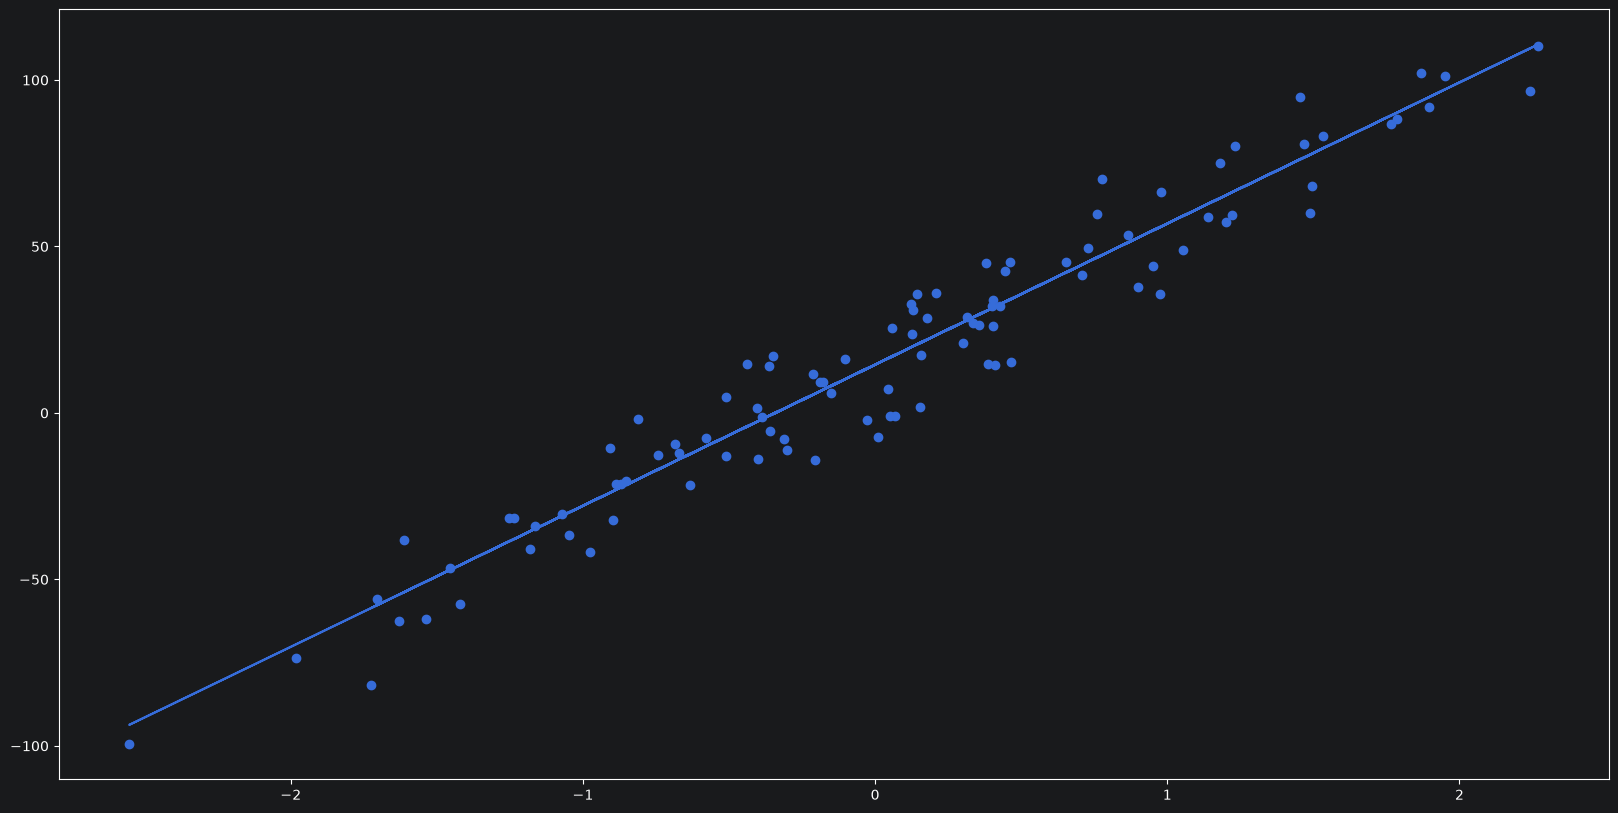

权重:42.38550485581797,偏置:14.5


In [41]:
import torch
from matplotlib import pyplot as plt
from sklearn.datasets import make_regression  # 创建数据集
from torch import (
    nn,  # nn模块中有平方根损失函数和假设函数
    optim,  # optim模块中有优化器函数
)
from torch.utils.data import DataLoader, TensorDataset, dataloader  # 构造数据集对象，数据集加载器

# 1.创建数据集
x, y, coef = make_regression(
    n_samples=100,
    n_features=1,
    noise=10,
    coef=True,
    bias=14.5,
    random_state=0,
)

x = torch.tensor(x, dtype=torch.float)
y = torch.tensor(y, dtype=torch.float).reshape(-1, 1)
x_np = x.detach().cpu().numpy()

# 数据可视化
plt.figure(figsize=(20, 10))
plt.scatter(x, y)
plt.plot(x_np, x_np * coef + 14.5)
plt.show()

print(f'权重:{coef},偏置:{14.5}')

In [42]:
# 2.模型训练
# 加载数据集
dataset = TensorDataset(x, y)
# 转入数据加载器
dataloader = DataLoader(dataset, batch_size=16, shuffle=True)
# 创建线性回归模型
model = nn.Linear(in_features=1, out_features=1)
# 创建损失函数对象
criterion = nn.MSELoss()
# 创建优化器对象
optimizer = optim.SGD(model.parameters(), lr=0.01)

epochs = 100
loss_list = []
for epoch in range(epochs):
    # 统计该轮次的loss
    total_loss, total_sample = 0.0, 0
    # 批次训练
    for x_train, y_train in dataloader:
        # 梯度清零
        optimizer.zero_grad()

        # 模型预测
        y_pred = model(x_train)
        # 计算损失值
        loss = criterion(y_pred, y_train)
        # 统计 总损失值 和 批次数
        total_loss += loss.item()
        total_sample += 1

        # 反向传播
        loss.sum().backward()
        optimizer.step()  # 梯度更新

    # 打印每轮数据
    loss_list.append(total_loss / total_sample)
    print(f'第{epoch + 1}轮,loss={loss_list[-1]}')

# 打印训练后数据
print(f'参数模型:权重:{model.weight},偏置:{model.bias}')

第1轮,loss=2101.4073486328125
第2轮,loss=1503.6654401506696
第3轮,loss=1133.1653703962054
第4轮,loss=838.3182591029575
第5轮,loss=758.919939313616
第6轮,loss=482.3306339808873
第7轮,loss=419.0808846609933
第8轮,loss=318.6473279680525
第9轮,loss=284.66707720075334
第10轮,loss=220.29433025632585
第11轮,loss=204.46732439313615
第12轮,loss=173.38942745753698
第13轮,loss=181.58165087018693
第14轮,loss=154.8414366585868
第15轮,loss=152.86398424421037
第16轮,loss=146.6242937360491
第17轮,loss=122.78952135358539
第18轮,loss=139.66149139404297
第19轮,loss=124.1248299734933
第20轮,loss=121.61199951171875
第21轮,loss=118.31665910993304
第22轮,loss=116.450441632952
第23轮,loss=112.0015117100307
第24轮,loss=125.82731519426618
第25轮,loss=104.83971296037946
第26轮,loss=124.44772338867188
第27轮,loss=109.69987978254046
第28轮,loss=125.14162881033761
第29轮,loss=117.28306034633091
第30轮,loss=115.26118578229632
第31轮,loss=121.68848255702427
第32轮,loss=107.85815756661552
第33轮,loss=121.34804425920758
第34轮,loss=131.29445103236608
第35轮,loss=113.56515066964286
第36轮,l

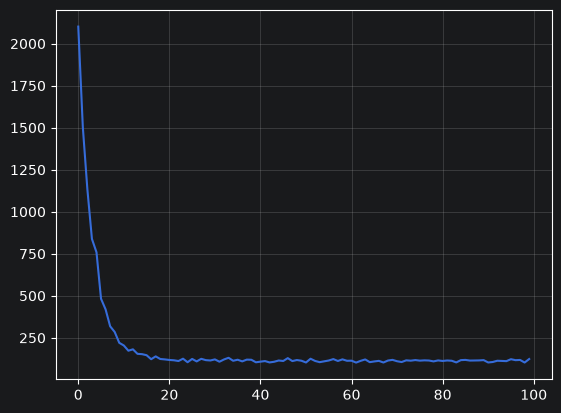

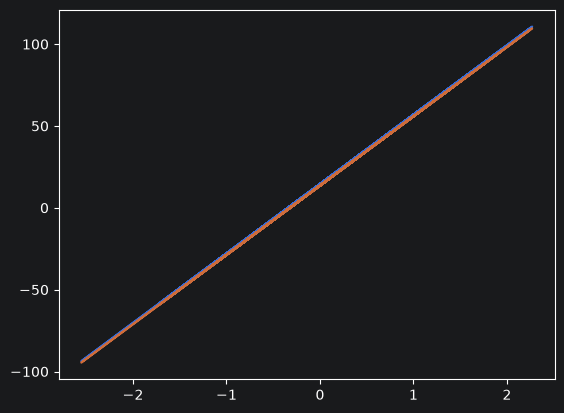

In [43]:
# 3.模型数据可视化
# 绘制损失函数
plt.plot(range(epochs), loss_list)
plt.grid(True, alpha=0.3)
plt.show()
# 绘制预测值与真实值的关系
# 剥离梯度，转到 CPU，再转 numpy
y_pred_np = model(x).detach().cpu().numpy()
plt.plot(x_np, x_np * coef + 14.5)  # 真实值的拟合线
plt.plot(x_np, y_pred_np)  # 预测值的拟合线
plt.show()
